# Phase 2 Task 4: Degradation Re-run with Final Pipeline

**Objective:** Evaluate model robustness to spatial degradation (16px, blur)

**Date:** 30-09-2026

**Background:** Test how well models perform when spatial details are destroyed

## 1. Setup

In [1]:
from pathlib import Path
import sys

CWD = Path.cwd()
for i, part in enumerate(CWD.parts):
    if part == 'woodbench':
        ROOT = Path(*CWD.parts[:i+1])
        break
else:
    ROOT = CWD

sys.path.insert(0, str(ROOT))

import torch
import timm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

print(f"ROOT: {ROOT}")
print(f"CUDA: {torch.cuda.is_available()}")

ROOT: /home/sakana/Code/ManifoldsTeam/woodbench
CUDA: True


## 2. Load ConvNeXt-Tiny Checkpoint

In [2]:
# Load ConvNeXt-Tiny checkpoint
CHECKPOINT = ROOT / "data/experiments/Task-B-new/19-08-2026/main/seed_42/convnext_tiny/convnext_tiny_seed42_best.pth"

# Load checkpoint (contains training metadata)
checkpoint = torch.load(CHECKPOINT, map_location='cpu')

# Extract model state dict
if 'model_state_dict' in checkpoint:
    state_dict = checkpoint['model_state_dict']
    print(f"Loaded checkpoint with keys: epoch={checkpoint.get('epoch')}, best_val_acc={checkpoint.get('best_val_acc')}")
else:
    # Pure state dict
    state_dict = checkpoint
    print("Loaded pure state dict")

model = timm.create_model('convnext_tiny', pretrained=False, num_classes=17)
model.load_state_dict(state_dict)
model = model.cuda()
model.eval()

print(f"Loaded ConvNeXt-Tiny from {CHECKPOINT}")

Loaded checkpoint with keys: epoch=13, best_val_acc=99.88925802879291
Loaded ConvNeXt-Tiny from /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/Task-B-new/19-08-2026/main/seed_42/convnext_tiny/convnext_tiny_seed42_best.pth


## 3. Define Degradation Transforms

In [3]:
import torchvision.transforms as T

class Degrade16x16:
    """Resize to 16x16 and back - destroys spatial info"""
    def __init__(self, target_size=224):
        self.resize_small = T.Resize((16, 16), interpolation=T.InterpolationMode.BILINEAR)
        self.resize_large = T.Resize((target_size, target_size), interpolation=T.InterpolationMode.BILINEAR)
    
    def __call__(self, img):
        img_small = self.resize_small(img)
        return self.resize_large(img_small)


class GaussianBlurTransform:
    """Apply Gaussian blur - reduces sharpness"""
    def __init__(self, sigma=5.0):
        self.blur = T.GaussianBlur(kernel_size=11, sigma=sigma)
    
    def __call__(self, img):
        return self.blur(img)


class ToTensorNormalize:
    """Convert to tensor and normalize"""
    def __init__(self):
        self.normalize = T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    
    def __call__(self, img):
        tensor = T.ToTensor()(img)
        return self.normalize(tensor)


# Define degradation levels
DEGRADATIONS = {
    'original': T.Compose([
        T.Resize(256),
        T.CenterCrop(224),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ]),
    
    '16x16': T.Compose([
        Degrade16x16(target_size=224),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ]),
    
    'blur_5': T.Compose([
        T.Resize(256),
        T.CenterCrop(224),
        GaussianBlurTransform(sigma=5.0),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ]),
    
    'blur_10': T.Compose([
        T.Resize(256),
        T.CenterCrop(224),
        GaussianBlurTransform(sigma=10.0),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ]),
}

print("Degradation transforms:")
for name in DEGRADATIONS:
    print(f"  - {name}")

Degradation transforms:
  - original
  - 16x16
  - blur_5
  - blur_10


## 4. Load Test Dataset

In [4]:
from torch.utils.data import Dataset, DataLoader

class TestDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.samples = []
        self.transform = transform
        
        classes = sorted([d.name for d in root_dir.iterdir() if d.is_dir()])
        self.classes = classes
        self.class_to_idx = {c: i for i, c in enumerate(classes)}
        
        for class_dir in sorted(root_dir.iterdir()):
            if class_dir.is_dir():
                for img_path in class_dir.glob("*.png"):
                    self.samples.append((str(img_path), self.class_to_idx[class_dir.name]))
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label

test_dir = ROOT / "data/task-B-group-split/test"
test_dataset = TestDataset(test_dir)

print(f"Test set: {len(test_dataset)} samples")
print(f"Classes: {test_dataset.classes}")

Test set: 532 samples
Classes: ['Araucaria araucana', 'Callitris columellaris', 'Calocedrus rupestris', 'Chamaecyparis obtusa', 'Cryptomeria japonica', 'Cunninghamia lanceolata', 'Fokienia hodginsii', 'Picea glauca', 'Pinus cernua', 'Pinus dalatensis', 'Pinus krempfii', 'Pinus radiata', 'Podocarpus pilgeri', 'Pseudotsuga brevifolia', 'Taxus wallichiana', 'Thujopsis dolabrata', 'Xanthocyparis vietnamensis']


## 5. Visual Examples of Degradations

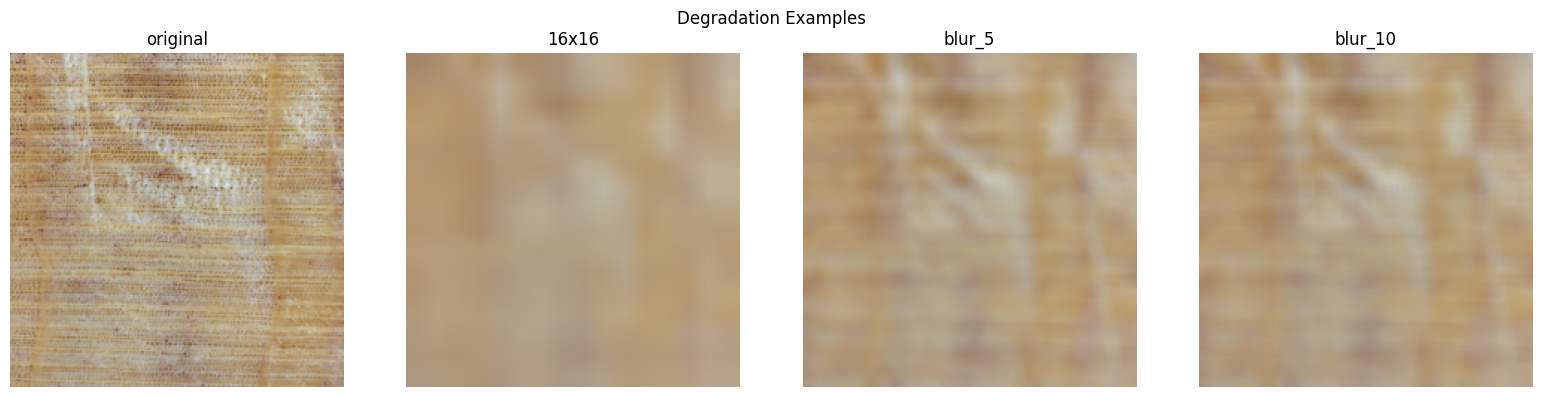

In [5]:
# Load a sample image
sample_paths = list(test_dir.glob("**/*.png"))[:1]
sample_img = Image.open(sample_paths[0]).convert('RGB')

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for idx, (name, transform) in enumerate(DEGRADATIONS.items()):
    # Get image before normalization
    if name == 'original':
        degraded = transform(sample_img)
        degraded = degraded.permute(1, 2, 0).numpy()
        degraded = degraded * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    elif name.startswith('blur'):
        # Apply resize + blur + convert
        img = sample_img.resize((224, 224))
        blurred = T.GaussianBlur(kernel_size=11, sigma=float(name.split('_')[1]))(img)
        degraded = np.array(blurred) / 255.0
    elif name == '16x16':
        degraded_small = sample_img.resize((16, 16), Image.BILINEAR)
        degraded = np.array(degraded_small.resize((224, 224), Image.BILINEAR)) / 255.0
    
    degraded = np.clip(degraded, 0, 1)
    axes[idx].imshow(degraded)
    axes[idx].set_title(name, fontsize=12)
    axes[idx].axis('off')

plt.suptitle('Degradation Examples')
plt.tight_layout()
plt.savefig('degradation_examples.png', dpi=150)
plt.show()

## 6. Run Degradation Evaluation

In [6]:
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score, classification_report

results = []

for deg_name, transform in DEGRADATIONS.items():
    print(f"\n=== Testing: {deg_name} ===")
    
    test_dataset.transform = transform
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
    
    all_preds = []
    all_labels = []
    
    for images, labels in tqdm(test_loader, desc=deg_name):
        images = images.cuda()
        
        with torch.no_grad():
            outputs = model(images)
            preds = outputs.argmax(dim=1).cpu().numpy()
        
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())
    
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='macro')
    
    results.append({
        'degradation': deg_name,
        'accuracy': acc,
        'macro_f1': f1,
        'n_samples': len(all_labels)
    })
    
    print(f"  Accuracy: {acc:.4f} ({acc*100:.2f}%)")
    print(f"  Macro F1: {f1:.4f}")


=== Testing: original ===


original:   0%|          | 0/17 [00:00<?, ?it/s]

  Accuracy: 0.9850 (98.50%)
  Macro F1: 0.9854

=== Testing: 16x16 ===


16x16:   0%|          | 0/17 [00:00<?, ?it/s]

  Accuracy: 0.2744 (27.44%)
  Macro F1: 0.1561

=== Testing: blur_5 ===


blur_5:   0%|          | 0/17 [00:00<?, ?it/s]

  Accuracy: 0.5695 (56.95%)
  Macro F1: 0.5519

=== Testing: blur_10 ===


blur_10:   0%|          | 0/17 [00:00<?, ?it/s]

  Accuracy: 0.5489 (54.89%)
  Macro F1: 0.5300


## 7. Results Summary

In [7]:
results_df = pd.DataFrame(results)

baseline_acc = results_df[results_df['degradation'] == 'original']['accuracy'].values[0]
results_df['drop_from_baseline'] = baseline_acc - results_df['accuracy']

print("\n" + "="*60)
print("DEGRADATION RESULTS")
print("="*60)
print(f"\nBaseline (original): {baseline_acc:.4f} ({baseline_acc*100:.2f}%)")

print("\n--- Results ---")
for _, row in results_df.iterrows():
    if row['degradation'] != 'original':
        drop = row['drop_from_baseline']
        print(f"\n{row['degradation']}:")
        print(f"  Accuracy: {row['accuracy']:.4f} ({row['accuracy']*100:.2f}%)")
        print(f"  Macro F1: {row['macro_f1']:.4f}")
        print(f"  Drop: {drop:.4f} ({drop*100:+.2f}%)")
        
        # Interpretation
        if drop > 0.3:
            print(f"  ⚠️  MAJOR: Model heavily relies on this feature")
        elif drop > 0.1:
            print(f"  ⚠️  MODERATE: Model uses this feature somewhat")
        elif drop > 0.02:
            print(f"  ✓  MINOR: Model is fairly robust")
        else:
            print(f"  ✓  ROBUST: Model is highly robust to this")


DEGRADATION RESULTS

Baseline (original): 0.9850 (98.50%)

--- Results ---

16x16:
  Accuracy: 0.2744 (27.44%)
  Macro F1: 0.1561
  Drop: 0.7105 (+71.05%)
  ⚠️  MAJOR: Model heavily relies on this feature

blur_5:
  Accuracy: 0.5695 (56.95%)
  Macro F1: 0.5519
  Drop: 0.4154 (+41.54%)
  ⚠️  MAJOR: Model heavily relies on this feature

blur_10:
  Accuracy: 0.5489 (54.89%)
  Macro F1: 0.5300
  Drop: 0.4361 (+43.61%)
  ⚠️  MAJOR: Model heavily relies on this feature


## 8. Visualize Results

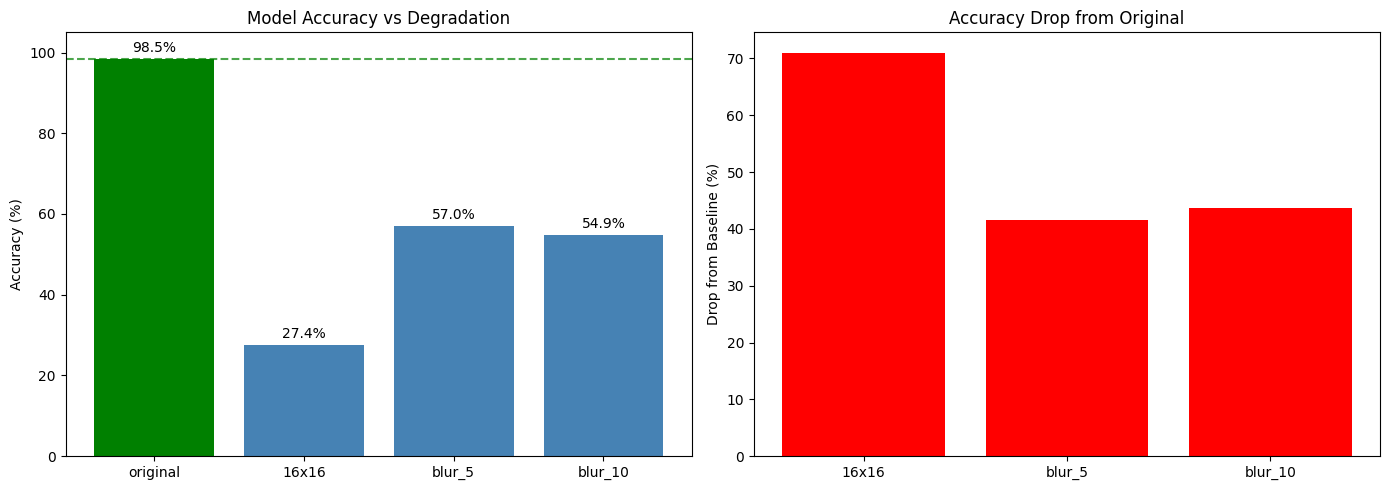

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy bar chart
ax = axes[0]
degs = results_df['degradation'].values
accs = results_df['accuracy'].values * 100
colors = ['green' if d == 'original' else 'steelblue' for d in degs]

bars = ax.bar(range(len(degs)), accs, color=colors)
ax.set_xticks(range(len(degs)))
ax.set_xticklabels(degs)
ax.set_ylabel('Accuracy (%)')
ax.set_title('Model Accuracy vs Degradation')
ax.set_ylim(0, 105)
ax.axhline(y=baseline_acc*100, color='green', linestyle='--', alpha=0.7)

for bar, acc in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, 
            f'{acc:.1f}%', ha='center', va='bottom')

# Drop from baseline
ax = axes[1]
drops = results_df['drop_from_baseline'].values * 100
drops_nonbaseline = drops[1:]  # Exclude baseline
degs_nonbaseline = degs[1:]

colors = ['red' if d > 10 else 'orange' if d > 3 else 'green' for d in drops_nonbaseline]
bars = ax.bar(range(len(drops_nonbaseline)), drops_nonbaseline, color=colors)
ax.set_xticks(range(len(degs_nonbaseline)))
ax.set_xticklabels(degs_nonbaseline)
ax.set_ylabel('Drop from Baseline (%)')
ax.set_title('Accuracy Drop from Original')

plt.tight_layout()
plt.savefig('degradation_results.png', dpi=150)
plt.show()

## 9. Conclusions

In [9]:
print("""
============================================================
DEGRADATION TEST CONCLUSIONS
============================================================

Key Findings:
""")

for _, row in results_df.iterrows():
    if row['degradation'] != 'original':
        drop = row['drop_from_baseline'] * 100
        if drop > 30:
            print(f"• {row['degradation']}: MAJOR drop ({drop:+.1f}%) - model relies heavily on spatial features")
        elif drop > 10:
            print(f"• {row['degradation']}: MODERATE drop ({drop:+.1f}%) - spatial features are important")
        elif drop > 3:
            print(f"• {row['degradation']}: MINOR drop ({drop:+.1f}%) - model is somewhat robust")
        else:
            print(f"• {row['degradation']}: ROBUST ({drop:+.1f}%) - model handles this well")

print("""
============================================================

Implications for Paper:
1. If 16x16 causes large drop: Model relies on fine-grained spatial patterns
2. If blur causes large drop: Model relies on high-frequency textures
3. Use these findings in Discussion section on model interpretation

============================================================
""")

# Save results
results_df.to_csv('degradation_results.csv', index=False)
print("Saved: degradation_results.csv")


DEGRADATION TEST CONCLUSIONS

Key Findings:

• 16x16: MAJOR drop (+71.1%) - model relies heavily on spatial features
• blur_5: MAJOR drop (+41.5%) - model relies heavily on spatial features
• blur_10: MAJOR drop (+43.6%) - model relies heavily on spatial features


Implications for Paper:
1. If 16x16 causes large drop: Model relies on fine-grained spatial patterns
2. If blur causes large drop: Model relies on high-frequency textures
3. Use these findings in Discussion section on model interpretation


Saved: degradation_results.csv
